In [1]:
from hamilton import driver
from hamilton.execution import executors

import rayfish
import rayfish.quantum_fisher_information as qfi
from rayfish.classical_fisher_information import (
    incoherent as classical_incoherent_sources,
)
from rayfish.classical_fisher_information.measurement_basis import (
    hermite_gaussian_basis,
)
from rayfish.di_fisher_information import (
    incoherent as di_incoherent_sources,
)
from rayfish.parameter_catalogue import distance_3_sources_xz
from rayfish.quantum_fisher_information import (
    incoherent_sources as qfi_incoherent_sources,
)

In [2]:
conf = {
    "simulation_dimension": 1,
}
n_grids = 50
mode_degree = 4
input_ = {
    "wave_vector": 2.0,
    "rayleigh_length": 1.0,
    "number_of_grids": n_grids,  # 50,
    "maximal_length": 14.0,
    "minimal_spacing": 0.1,
    "min_z_displacement": 0.1,
    "max_z_displacement": 2.0,
    "mode_degree": mode_degree,
    "numerical_integration_resolution": 12,
    "numerical_integration_support": 5.0,
    "batch_size": 250,
}

In [3]:
quantum_dr = (
    driver.Builder()
    .with_modules(rayfish, qfi, qfi_incoherent_sources, distance_3_sources_xz)
    .with_config(config=conf)
    .enable_dynamic_execution(allow_experimental_mode=True)
    .with_local_executor(executors.SynchronousLocalTaskExecutor())
).build()

classical_dr = (
    driver.Builder()
    .with_modules(
        rayfish,
        classical_incoherent_sources,
        distance_3_sources_xz,
        hermite_gaussian_basis,
    )
    .with_config(config=conf)
).build()

di_dr = (
    driver.Builder()
    .with_modules(
        rayfish,
        di_incoherent_sources,
        distance_3_sources_xz,
    )
    .with_config(config=conf)
).build()

In [ ]:
# quantum_result = quantum_dr.execute(
#     inputs=input_,
#     final_vars=[
#         "fisher_information_matrix_for_entire_distribution",
#         "covariance_matrix_for_entire_distribution",
#         "number_of_point_sources",
#         "spacing",
#         "coordinates",
#     ],
# )

# classical_result = classical_dr.execute(
#     inputs=input_,
#     final_vars=[
#         "fisher_information_matrix_for_entire_distribution",
#         "covariance_matrix_for_entire_distribution",
#         "number_of_point_sources",
#         "spacing",
#         "coordinates",
#         "measurement_basis",
#     ],
# )

# di_result = di_dr.execute(
#     inputs=input_,
#     final_vars=[
#         "fisher_information_matrix_for_entire_distribution",
#         "covariance_matrix_for_entire_distribution",
#         "number_of_point_sources",
#         "spacing",
#         "coordinates",
#     ],
# )

In [5]:
import numpy as np

In [6]:
# qfi_ = np.real(
#     quantum_result["fisher_information_matrix_for_entire_distribution"].reshape(
#         n_grids, n_grids, 2, 2
#     )
# )
# np.save(
#     "qfi.npy",
#     qfi_,
# )

# qfi_inv_ = np.real(
#     quantum_result["covariance_matrix_for_entire_distribution"].reshape(
#         n_grids, n_grids, 2, 2
#     )
# )
# np.save(
#     "qfi_inv.npy",
#     qfi_inv_,
# )
qfi_ = np.load("qfi.npy")
qfi_inv_ = np.load("qfi_inv.npy")

In [7]:
# fi_ms_ = classical_result["fisher_information_matrix_for_entire_distribution"]
# .reshape(
#     n_grids, n_grids, mode_degree * mode_degree, 2, 2
# )
# np.save(
#     "fi_ms.npy",
#     fi_ms_,
# )

# fi_ms_inv_ = classical_result["covariance_matrix_for_entire_distribution"].reshape(
#     n_grids, n_grids, 2, 2
# )
# np.save(
#     "fi_ms_inv.npy",
#     fi_ms_inv_,
# )
# fi_ms_ = np.load("fi_ms.npy")
# fi_ms_inv_ = np.load("fi_ms_inv.npy")

fi_ms_ = np.load("fi_ms_-1.npy")
fi_ms_inv_ = np.load("fi_ms_inv_-1_with_remainder.npy")

In [8]:
# fi_di_ = di_result["fisher_information_matrix_for_entire_distribution"].reshape(
#     n_grids, n_grids, 2, 2
# )
# np.save(
#     "fi_di.npy",
#     fi_di_,
# )

# fi_di_inv_ = di_result["covariance_matrix_for_entire_distribution"].reshape(
#     n_grids, n_grids, 2, 2
# )
# np.save(
#     "fi_di_inv.npy",
#     fi_di_inv_,
# )
fi_di_ = np.load("fi_di.npy")
fi_di_inv_ = np.load("fi_di_inv.npy")

In [9]:
coords_result = di_dr.execute(
    inputs=input_,
    final_vars=[
        "coordinates",
    ],
)
coords = coords_result["coordinates"].reshape(n_grids, n_grids, 9)
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

In [10]:
%matplotlib inline

In [11]:
import matplotlib.pyplot as plt

from visualize_helpers import create_fig_and_ax, latexify, plot_individual_fi

In [12]:
latexify()

In [13]:
FORMAT = "pdf"

# s param

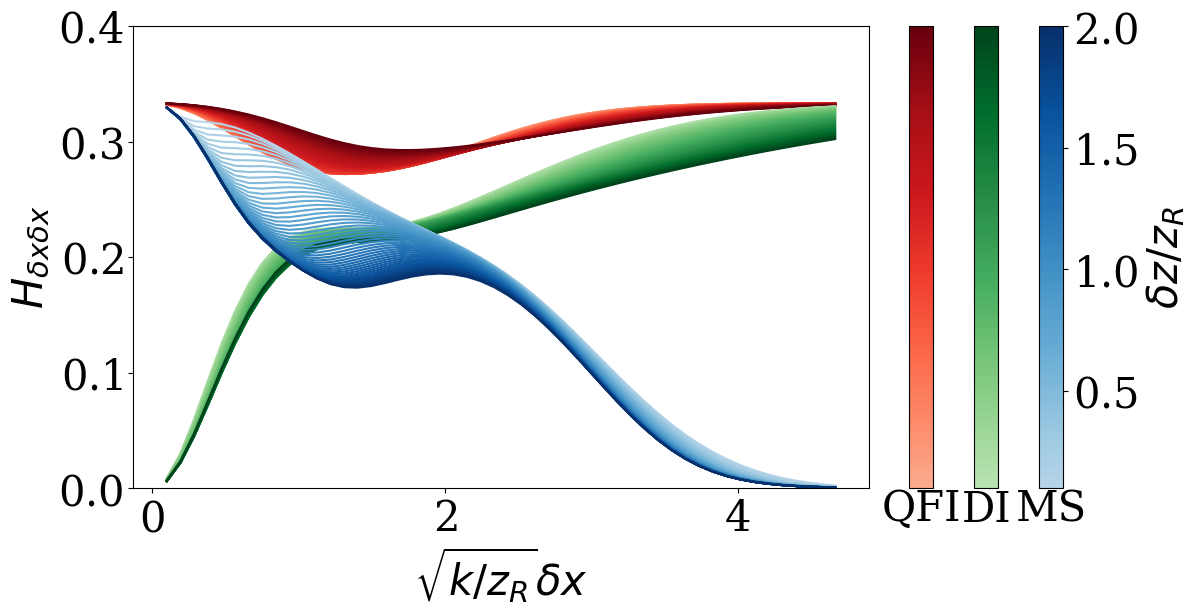

In [14]:
fig, axs = create_fig_and_ax(3)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, fi_di_[:, :, 0, 0], x_range, p_range, "Greens", 2, "DI"
)
ms_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[0].set_ylim(0, 0.4)
axs[3].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

fig.savefig(
    f"s_param_fi_comparison_optimal_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

In [20]:
# Whitelist of continuous colormaps suitable for publication
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "plasma",
    "viridis",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
    "Blues",
]


def filter_pub_friendly_continuous(
    max_rgb: float = 1, sample_points: int = 256
) -> list:
    """Good colors for plots."""
    good_cmaps = []
    for name in continuous_cmaps:
        cmap = plt.get_cmap(name)
        colors = cmap(np.linspace(0, 1, sample_points))[:, :3]  # RGB only
        if np.any(colors > max_rgb):
            continue  # skip overly bright colors
        good_cmaps.append(name)
    return good_cmaps

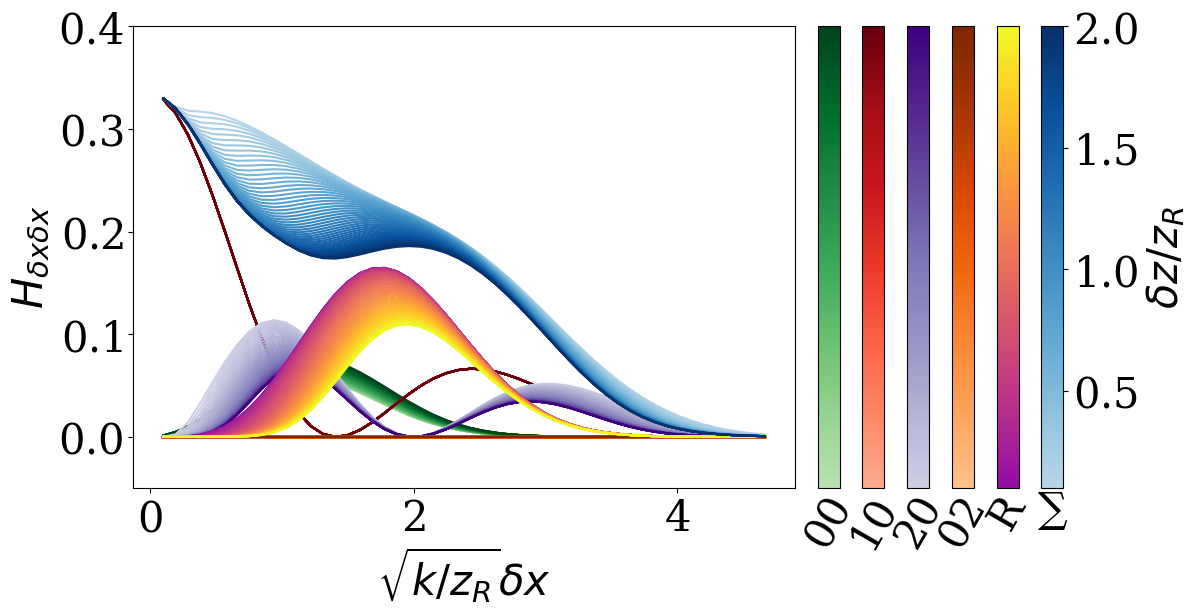

In [21]:
n_modes = fi_ms_.shape[2]
good_cmaps = filter_pub_friendly_continuous()
IMPORTANT_MODES = ((0, 0), (1, 0), (2, 0), (0, 2))

n_axes = len(IMPORTANT_MODES) + 1
fig, axs = create_fig_and_ax(n_axes + 1)

for idx, mode in enumerate(IMPORTANT_MODES):
    (i, j) = mode
    plot_individual_fi(
        fig,
        axs,
        fi_ms_[:, :, idx, 0, 0],
        x_range,
        p_range,
        good_cmaps[idx],
        idx + 1,
        f"{i}{j}",
        rotation=60,
    )

plot_individual_fi(
    fig,
    axs,
    fi_ms_[:, :, -1, 0, 0],
    x_range,
    p_range,
    good_cmaps[len(IMPORTANT_MODES)],
    len(IMPORTANT_MODES) + 1,
    r"R",
    rotation=60,
)

sum_cm = plot_individual_fi(
    fig,
    axs,
    np.sum(fi_ms_, axis=2)[:, :, 0, 0],
    x_range,
    p_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[0].set_ylim(-0.05, 0.4)
axs[n_axes + 1].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H_{\delta x \delta x}$")

fig.savefig(
    f"s_param_individual_mode_contributions_optimal_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

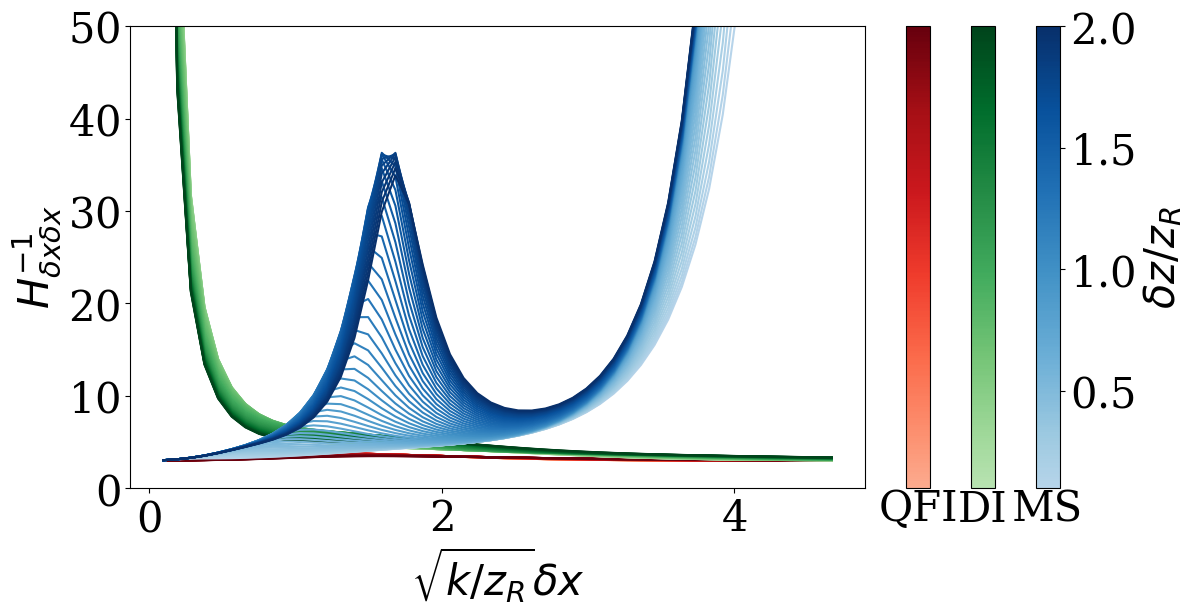

In [22]:
fig, axs = create_fig_and_ax(3)
qfi_cm = plot_individual_fi(
    fig, axs, qfi_inv_[:, :, 0, 0], x_range, p_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, fi_di_inv_[:, :, 0, 0], x_range, p_range, "Greens", 2, "DI"
)
ms_cm = plot_individual_fi(
    fig, axs, fi_ms_inv_[:, :, 0, 0], x_range, p_range, "Blues", 3, "MS", False
)

axs[0].set_ylim(0, 50)
axs[3].set_ylabel(r"$\delta z / z_R$")
axs[0].set_xlabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_ylabel(r"$H^{-1}_{\delta x \delta x}$")

fig.savefig(
    f"s_param_covariance_optimal_remainder.{FORMAT}", format=FORMAT, bbox_inches="tight"
)
plt.show()

# p param

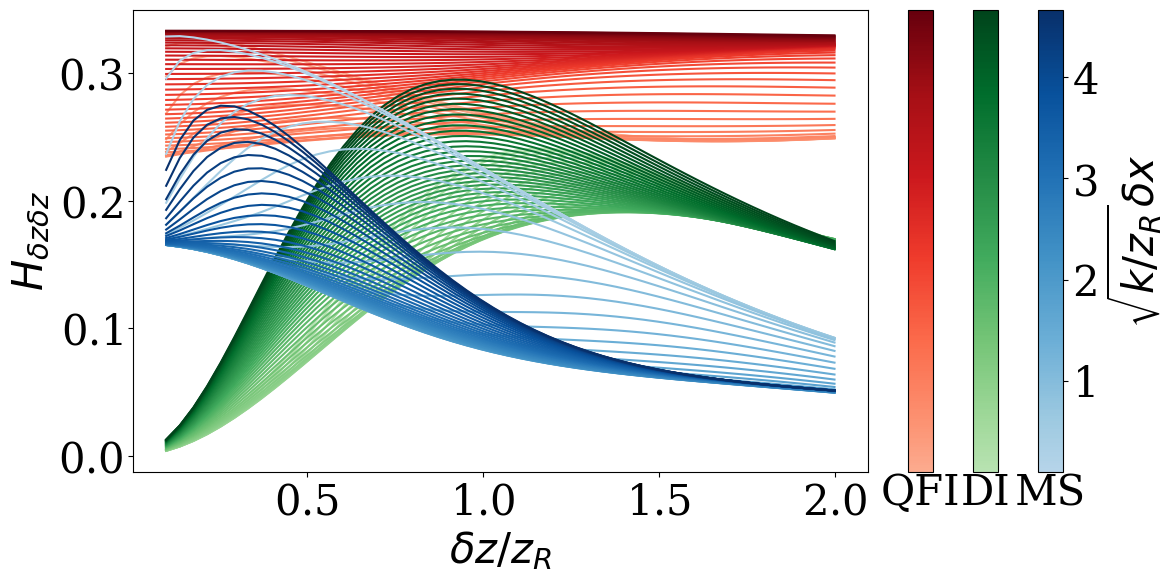

In [23]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")


fig.savefig(
    f"p_param_fi_comparison_optimal_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)

plt.show()

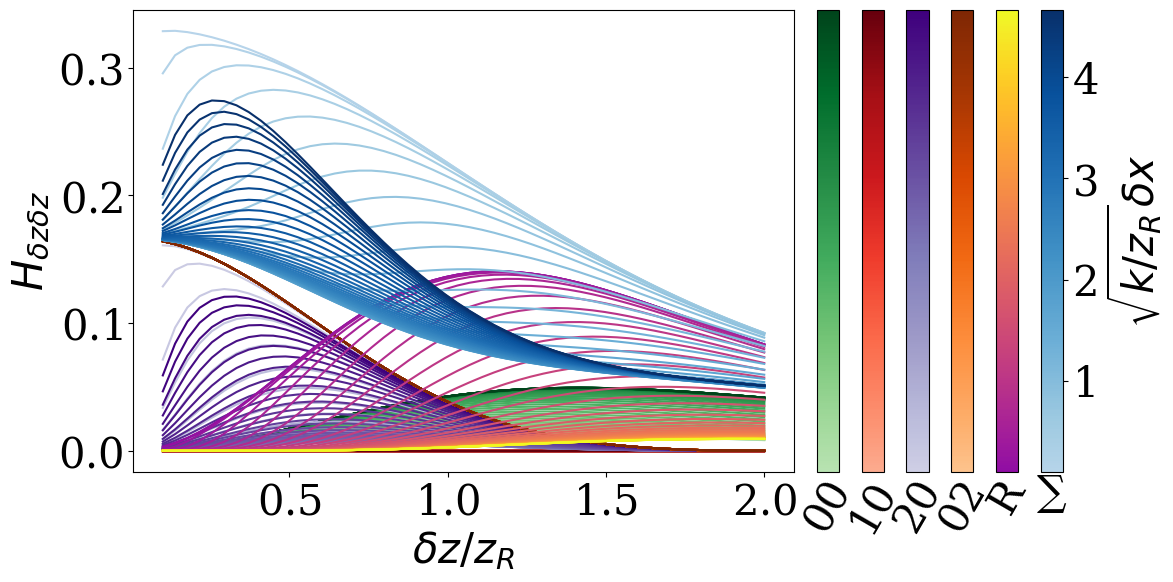

In [24]:
good_cmaps = filter_pub_friendly_continuous()
IMPORTANT_MODES = ((0, 0), (1, 0), (2, 0), (0, 2))

n_axes = len(IMPORTANT_MODES) + 1
fig, axs = create_fig_and_ax(n_axes + 1)

for idx, mode in enumerate(IMPORTANT_MODES):
    (i, j) = mode
    plot_individual_fi(
        fig,
        axs,
        np.transpose(fi_ms_[:, :, idx, 1, 1]),
        p_range,
        x_range,
        good_cmaps[idx],
        idx + 1,
        f"{i}{j}",
        rotation=60,
    )

plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_[:, :, -1, 1, 1]),
    p_range,
    x_range,
    good_cmaps[len(IMPORTANT_MODES)],
    len(IMPORTANT_MODES) + 1,
    r"R",
    rotation=60,
)


plot_individual_fi(
    fig,
    axs,
    np.transpose(np.sum(fi_ms_, axis=2)[:, :, 1, 1]),
    p_range,
    x_range,
    good_cmaps[-1],
    n_axes + 1,
    "∑",
    False,
)


axs[n_axes + 1].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H_{\delta z \delta z}$")

fig.savefig(
    f"p_param_individual_mode_contributions_optimal_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

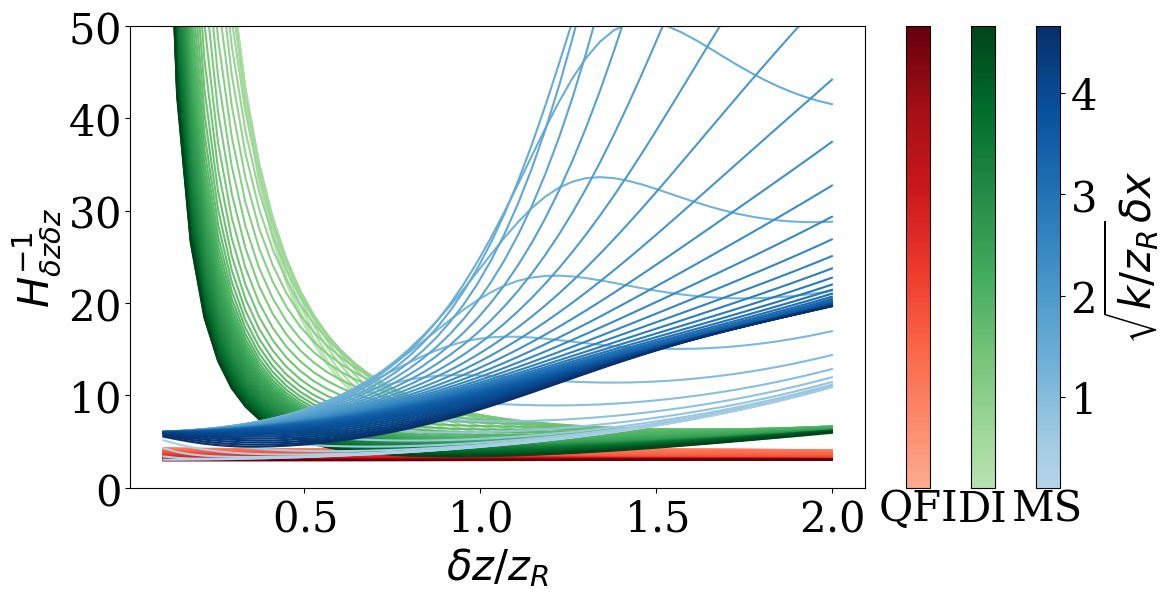

In [25]:
fig, axs = create_fig_and_ax(3)

qfi_cm = plot_individual_fi(
    fig, axs, np.transpose(qfi_inv_[:, :, 1, 1]), p_range, x_range, "Reds", 1, "QFI"
)
di_cm = plot_individual_fi(
    fig, axs, np.transpose(fi_di_inv_[:, :, 1, 1]), p_range, x_range, "Greens", 2, "DI"
)
qfi_cm = plot_individual_fi(
    fig,
    axs,
    np.transpose(fi_ms_inv_[:, :, 1, 1]),
    p_range,
    x_range,
    "Blues",
    3,
    "MS",
    False,
)

axs[0].set_ylim(0, 50)
axs[3].set_ylabel(r"$\sqrt{k/z_R} \delta x$")
axs[0].set_xlabel(r"$\delta z / z_R$")
axs[0].set_ylabel(r"$H^{-1}_{\delta z \delta z}$")

fig.savefig(
    f"p_param_covariance_optimal_remainder.{FORMAT}", format=FORMAT, bbox_inches="tight"
)
plt.show()